# Teaching a computer to read handwritten digits
**ICT Assignment #2: Computer Vision, Option A (improve the model on an open-source dataset)**
Student: **Bolat Rauan**, Stream 2, Practice 2

**Research question.** How much does each model change reduce mistakes in handwritten digit recognition?

**Dataset.** MNIST: 70 000 images of digits 0–9, 28×28 grayscale, built into Keras.

**Experiments.** One change at a time; everything else stays fixed (same split, seed 42, 5 epochs, batch size 128):

| # | Model | What changes |
|---|---|---|
| 1 | Logistic regression | baseline |
| 2 | MLP | + hidden layer (128 ReLU) |
| 3 | CNN, 1 conv, SGD | + convolution |
| 4 | CNN, 1 conv, Adam | optimizer SGD → Adam |
| 5 | CNN, 2 conv, Adam | + second conv layer |
| 6 | CNN, 2 conv, Adam, Dropout | + dropout 0.3 |

▶ To run: *Runtime → Run all* (about 2 min on CPU, faster with a GPU).

## 1. Setup and data
Pixels are scaled from 0–255 to 0–1, and a channel dimension is added for the CNN.

In [1]:
"""
ICT Assignment #2 — Computer Vision, Option A (improve the model on an open-source dataset)
Student: Bolat Rauan · Stream 2, Practice 2
Dataset: MNIST handwritten digits (60 000 train / 10 000 test, 28×28 grayscale) — open source, built into Keras.
Question: how much does each model change improve digit recognition?
"""
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED, EPOCHS, BATCH = 42, 5, 128
keras.utils.set_random_seed(SEED)

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = (x_train / 255.0).astype("float32")[..., None]      # pixels 0..1, shape (N, 28, 28, 1)
x_test = (x_test / 255.0).astype("float32")[..., None]
print("train:", x_train.shape, " test:", x_test.shape)


train: (60000, 28, 28, 1)  test: (10000, 28, 28, 1)


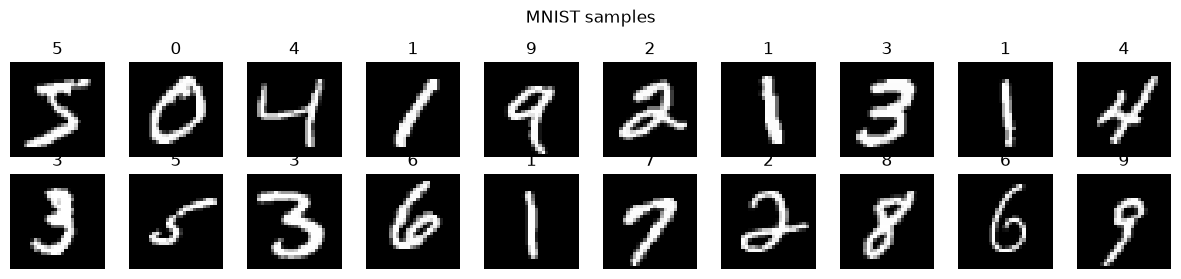

In [2]:
fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
for ax, i in zip(axes.flat, range(20)):
    ax.imshow(x_train[i, :, :, 0], cmap="gray"); ax.set_title(int(y_train[i])); ax.axis("off")
plt.suptitle("MNIST samples"); plt.tight_layout(); plt.show()


## 2. Models
- **Logistic regression:** `Flatten → Dense(10, softmax)`. Every pixel gets one weight per class.
- **MLP:** adds `Dense(128, relu)`, so the model can combine pixels into stroke parts.
- **CNN:** `Conv2D(3×3) → MaxPooling(2×2)`. Filters detect edges and curves anywhere in the image, and pooling makes the model less sensitive to small shifts.
- **Dropout:** randomly switches off 30% of neurons during training to reduce overfitting.

In [3]:
def logistic_regression():
    """Baseline: one Dense layer with softmax = multinomial logistic regression on 784 pixels."""
    return keras.Sequential([keras.Input((28, 28, 1)), layers.Flatten(), layers.Dense(10, activation="softmax")])


def mlp():
    """+ one hidden layer with ReLU: the model can learn non-linear combinations of pixels."""
    return keras.Sequential([keras.Input((28, 28, 1)), layers.Flatten(),
                             layers.Dense(128, activation="relu"), layers.Dense(10, activation="softmax")])


def cnn(conv_layers=1, dropout=0.0):
    """Convolutional network: 3×3 filters look for strokes and curves anywhere in the image."""
    m = [keras.Input((28, 28, 1))]
    for i, f in enumerate([32, 64][:conv_layers]):
        m += [layers.Conv2D(f, 3, activation="relu"), layers.MaxPooling2D(2)]
    m += [layers.Flatten()]
    if dropout:
        m += [layers.Dropout(dropout)]
    m += [layers.Dense(128, activation="relu")]
    if dropout:
        m += [layers.Dropout(dropout)]
    m += [layers.Dense(10, activation="softmax")]
    return keras.Sequential(m)


EXPERIMENTS = [
    # name,                          builder,                          optimizer,                     what changed
    ("1 Logistic regression",        logistic_regression,              "adam",                        "baseline"),
    ("2 MLP (1 hidden layer)",       mlp,                              "adam",                        "+ hidden layer"),
    ("3 CNN, 1 conv, SGD",           lambda: cnn(1),                   "sgd",                         "+ convolution"),
    ("4 CNN, 1 conv, Adam",          lambda: cnn(1),                   "adam",                        "SGD → Adam"),
    ("5 CNN, 2 conv, Adam",          lambda: cnn(2),                   "adam",                        "+ 2nd conv layer"),
    ("6 CNN, 2 conv, Adam, Dropout", lambda: cnn(2, dropout=0.3),      "adam",                        "+ dropout 0.3"),
]


## 3. Training
Each model starts from the same random seed. 10% of the training data is held out for validation. The test set is used only once, for the final score.

In [4]:
def make_opt(name):
    return keras.optimizers.SGD(learning_rate=0.01) if name == "sgd" else keras.optimizers.Adam(learning_rate=0.001)


results, histories, models = [], {}, {}
for name, build, opt, change in EXPERIMENTS:
    keras.utils.set_random_seed(SEED)                     # same start for a fair comparison
    model = build()
    model.compile(optimizer=make_opt(opt), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    h = model.fit(x_train, y_train, epochs=EPOCHS, batch_size=BATCH, validation_split=0.1, verbose=0)
    sec = time.time() - t0
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
    results.append({"model": name, "change": change, "params": model.count_params(),
                    "train_acc": h.history["accuracy"][-1], "val_acc": h.history["val_accuracy"][-1],
                    "test_acc": test_acc, "errors": int(round((1 - test_acc) * len(x_test))), "seconds": sec})
    histories[name], models[name] = h.history, model
    print(f"{name:30s} test acc {test_acc:.4f}  ({results[-1]['errors']} errors / 10000)  {sec:5.1f}s")


1 Logistic regression          test acc 0.9236  (764 errors / 10000)    2.9s


2 MLP (1 hidden layer)         test acc 0.9697  (303 errors / 10000)    4.0s


3 CNN, 1 conv, SGD             test acc 0.9392  (608 errors / 10000)   15.3s


4 CNN, 1 conv, Adam            test acc 0.9823  (177 errors / 10000)   15.0s


5 CNN, 2 conv, Adam            test acc 0.9898  (102 errors / 10000)   23.4s


6 CNN, 2 conv, Adam, Dropout   test acc 0.9903  (97 errors / 10000)   25.8s


## 4. Results

In [5]:
print(f"\n{'Model':30s} {'Change':18s} {'Params':>8s} {'Train':>7s} {'Val':>7s} {'Test':>7s} {'Errors':>7s} {'Time':>6s}")
for r in results:
    print(f"{r['model']:30s} {r['change']:18s} {r['params']:8d} {r['train_acc']:7.2%} {r['val_acc']:7.2%} "
          f"{r['test_acc']:7.2%} {r['errors']:7d} {r['seconds']:5.0f}s")
base, best = results[0], results[-1]
print(f"\nErrors on 10 000 test images: {base['errors']} → {best['errors']}  "
      f"({1 - best['errors'] / base['errors']:.0%} fewer mistakes)")



Model                          Change               Params   Train     Val    Test  Errors   Time
1 Logistic regression          baseline               7850  91.74%  93.50%  92.36%     764     3s
2 MLP (1 hidden layer)         + hidden layer       101770  97.86%  97.38%  96.97%     303     4s
3 CNN, 1 conv, SGD             + convolution        693962  92.97%  94.87%  93.92%     608    15s
4 CNN, 1 conv, Adam            SGD → Adam           693962  99.26%  98.42%  98.23%     177    15s
5 CNN, 2 conv, Adam            + 2nd conv layer     225034  99.27%  99.00%  98.98%     102    23s
6 CNN, 2 conv, Adam, Dropout   + dropout 0.3        225034  98.52%  99.15%  99.03%      97    26s

Errors on 10 000 test images: 764 → 97  (87% fewer mistakes)


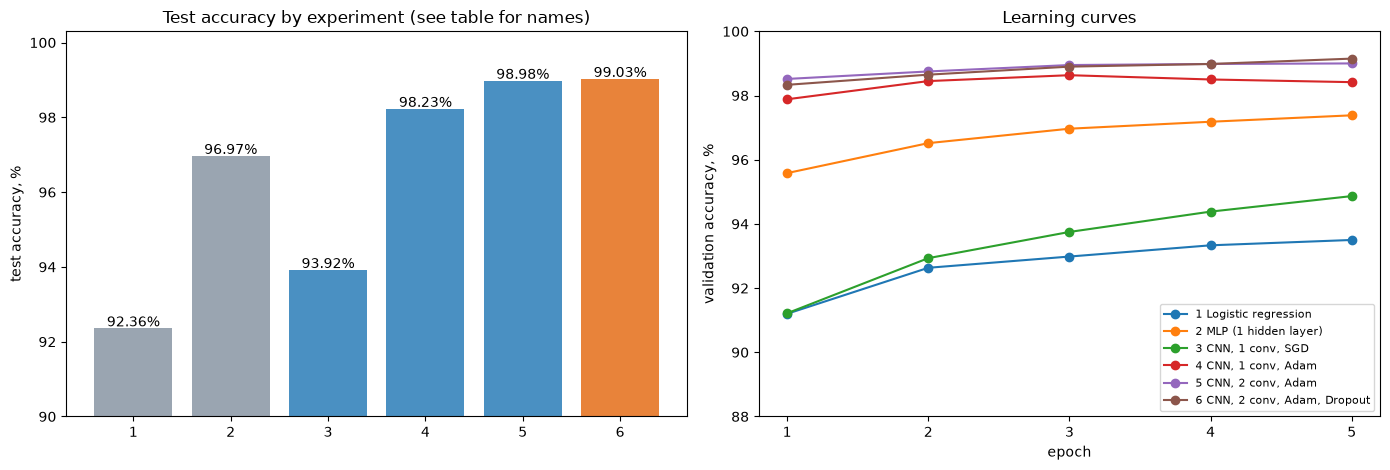

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
names = [r["model"].split(" ", 1)[0] for r in results]
acc = [r["test_acc"] * 100 for r in results]
bars = ax[0].bar(names, acc, color=["#9aa5b1"] * 2 + ["#4a90c2"] * 3 + ["#e8833a"])
for b, r in zip(bars, results):
    ax[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.05, f"{r['test_acc']:.2%}", ha="center", fontsize=10)
ax[0].set(ylim=(90, 100.3), ylabel="test accuracy, %", title="Test accuracy by experiment (see table for names)")
for r in results:
    ax[1].plot(range(1, EPOCHS + 1), np.array(histories[r["model"]]["val_accuracy"]) * 100, marker="o", label=r["model"])
ax[1].set(xlabel="epoch", ylabel="validation accuracy, %", title="Learning curves", ylim=(88, 100), xticks=range(1, EPOCHS + 1))
ax[1].legend(fontsize=8); plt.tight_layout(); plt.savefig("results.png", dpi=150); plt.show()


## 5. Error analysis of the final model

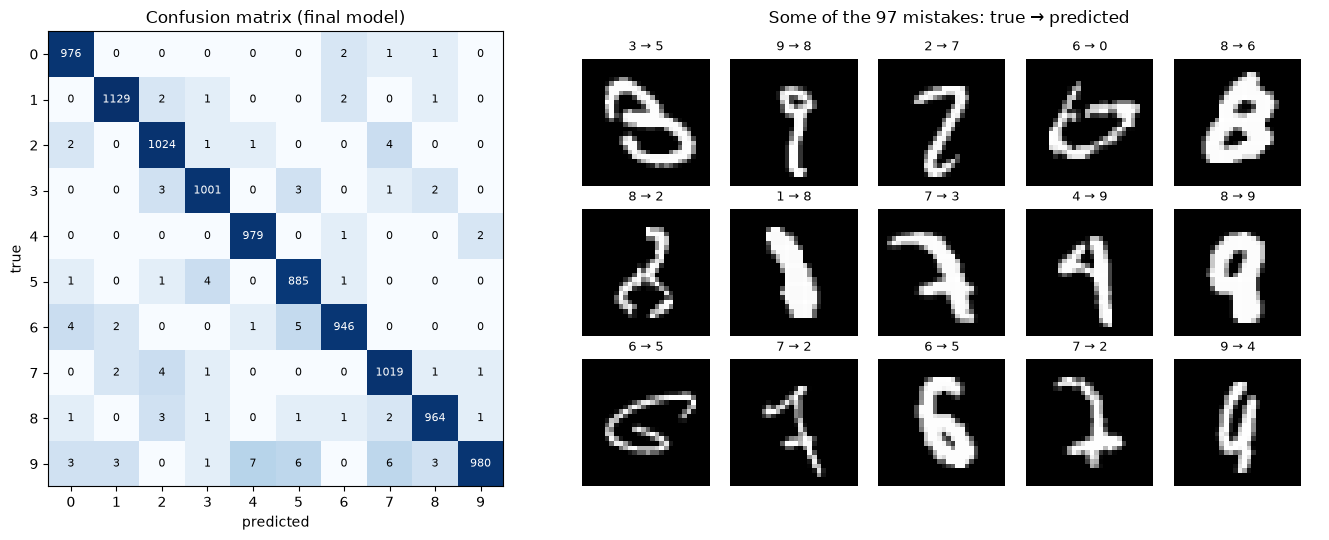

Most common confusion: true 9 predicted as 4 (7 times)


In [7]:
final = models[results[-1]["model"]]
pred = final.predict(x_test, verbose=0).argmax(1)
cm = tf.math.confusion_matrix(y_test, pred).numpy()
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.25]})
ax[0].imshow(np.log1p(cm), cmap="Blues")
for i in range(10):
    for j in range(10):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if i == j else "black")
ax[0].set(xticks=range(10), yticks=range(10), xlabel="predicted", ylabel="true", title="Confusion matrix (final model)")
wrong = np.where(pred != y_test)[0][:15]
ax[1].axis("off"); ax[1].set_title(f"Some of the {len(np.where(pred != y_test)[0])} mistakes: true → predicted")
for k, i in enumerate(wrong):
    sub = ax[1].inset_axes([(k % 5) * 0.2, 0.66 - (k // 5) * 0.33, 0.18, 0.28])
    sub.imshow(x_test[i, :, :, 0], cmap="gray"); sub.set_title(f"{y_test[i]} → {pred[i]}", fontsize=9); sub.axis("off")
plt.tight_layout(); plt.savefig("errors.png", dpi=150); plt.show()
off = cm - np.diag(np.diag(cm))
i, j = np.unravel_index(off.argmax(), off.shape)
print(f"Most common confusion: true {i} predicted as {j} ({off[i, j]} times)")


## 6. Save the model
The Keras model is saved, and its weights are exported to `model_weights.js` for the in-browser demo (`index.html`).

In [8]:
final.save("mnist_cnn.keras")
weights = {}
for layer in final.layers:
    w = layer.get_weights()
    if w:
        weights[layer.name] = {"kernel": np.round(w[0], 5).tolist(), "bias": np.round(w[1], 5).tolist(),
                               "shape": list(w[0].shape)}
with open("model_weights.js", "w") as f:
    f.write("window.MODEL_WEIGHTS = " + json.dumps(weights) + ";\n")
with open("results.json", "w") as f:
    json.dump({"results": results, "histories": {k: {kk: [float(x) for x in vv] for kk, vv in v.items()}
                                                   for k, v in histories.items()}}, f, indent=1)
print("saved: mnist_cnn.keras, model_weights.js (for the web demo), results.json")


saved: mnist_cnn.keras, model_weights.js (for the web demo), results.json


## 7. Conclusions
See the printed results above and the summary on the landing page (`index.html`). Key points:
1. Adding a hidden layer removes more than half of the baseline mistakes.
2. A CNN trained with plain SGD (lr 0.01, 5 epochs) was **worse** than the MLP. A better architecture does not help if the optimizer has not finished learning.
3. Switching the same CNN to Adam gave the largest improvement among the CNN experiments.
4. A second conv layer improved results further. Dropout gave a small extra gain, with a small train/test gap.

**Limitations:** single run per model (one seed), only 5 epochs, and clean centred digits.
**Next steps:** several seeds, data augmentation, early stopping, batch normalisation.

*AI use: an AI assistant (Claude) helped write and structure this code. I ran the experiments and can explain each step.*